(dose-response-guide)=
# Dose response per cell type

Find which genes respond to a dose in each cell type of a dose series, and how, with {api}`dose_response`. The series here is simulated from known curves by {api}`simulate_dose_series`, so its truth says which genes respond: 27 mice, 3 for the vehicle and for each of eight doses from 0.01 to 30 ug/kg in half-log steps, with hepatocytes, macrophages, stellate cells and cholangiocytes, of which 20%, 15%, 5% and 10% of 2,000 genes respond. Hepatocytes and stellate cells fall by half and macrophages double at the top dose, and cholangiocytes are rare. [Dose response](../statistics/dose_response.md) explains the methods.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool import Design, DoseAxis, DoseTruth, dose_response, read_cube
from cytepool.plotting import plot_dose_response

# The cube, and the truth of each cell type.
cube = read_cube("simulated_dose_series.cube.zarr")
truth = DoseTruth(**json.loads(Path("simulated_dose_series_truth.json").read_text()))
print(f"CytePool {cytepool.__version__}")
print(cube)

CytePool 0.1.1.dev18+gdcfb18fb8
Cube with 27 samples x 4 groups x 2,000 features
  layers: counts (uint32, lazy)
  filled: 108 of 108 sample x group entries have cells (100.0%)
  samples: sample_id, dose, dose_group, donor
  groups: group_id
  features: feature_id


Each sample is one mouse's pseudobulk profile in one cell type: the sum of its cells' counts. The sample table holds each mouse's `dose`, 0 for the vehicle.

## Place the doses on an axis

Where does each dose sit on the curve's axis? The doses are spaced by half a log10, so the curves follow log10 dose, and the vehicle, whose dose of 0 has no logarithm, forms a group of its own, the default of {api}`DoseAxis`:

In [2]:
axis = DoseAxis("dose", unit=truth.unit, metric=truth.metric)
print(axis)

DoseAxis(column='dose', unit='ug/kg', metric='administered', scale='log10', vehicle='own_group', offset=None)


## Test every cell type

Which genes respond in each cell type? {api}`dose_response` takes the design of the terms other than dose, here none (`"~ 1"`). It checks the design first, as {api}`check_dose_design` does, so that check needs no call of its own, and tests the cell types that support tests:

In [3]:
result = dose_response(cube, Design(cube.samples, "~ 1"), dose=axis)
print(result)

DoseResponseResult (limma_voom): 4 cell types, 3 tested; tests: spline (read
    first), nonlinearity, linear_trend, dose_groups
  dose: ug/kg (administered) on a log10 axis, the vehicle in a group of its own;
        spline of 2 columns, knots at 0.548 ug/kg, boundary knots at 0.01 and 30
        ug/kg; linear_trend slopes per log10 unit of dose
  Hepatocyte: 9 dose groups, 27 samples, 1,869 genes; calls at 5% FDR: spline
              230, nonlinearity 98, linear_trend 205, dose_groups 201
  Macrophage: 9 dose groups, 27 samples, 1,484 genes; calls at 5% FDR: spline
              113, nonlinearity 41, linear_trend 94, dose_groups 104
  Stellate: 9 dose groups, 27 samples, 845 genes; calls at 5% FDR: spline 17,
            nonlinearity 3, linear_trend 12, dose_groups 10
  Cholangiocyte: not tested, descriptive: no treated dose group that can be
                 compared with the vehicle keeps a second sample, so no dose has
                 a replicate


The printout gives the spline's knot in doses and, for each cell type, the dose groups it compares, its samples and genes, and the genes each test calls at 5% FDR. Read `spline` first: it asks whether a gene responds at all. `linear_trend` and `nonlinearity` describe the responses it finds, and `dose_groups` asks the same question as `spline` without a curve. The cholangiocytes are not tested: few of their profiles keep 10 cells, so no dose has a second replicate, and the check calls them descriptive. Its report stays in the result:

In [4]:
report = result.design_report
report.doses.filter(group_id="Cholangiocyte").select(
    ["dose", "n_samples_used", "n_cells_min"]
)

Table with 9 rows and 3 columns
  dose     n_samples_used  n_cells_min
  float64  int64           float64
  0.0      1               17.0
  0.01     0               nan
  0.03     1               13.0
  0.1      0               nan
  0.3      1               10.0
  1.0      1               11.0
  3.0      0               nan
  10.0     1               14.0
  30.0     1               13.0

## Read a test's table

What does each gene's row say? The table of a test has one row per gene that passes the expression filter, here the hepatocytes' spline sorted by p-value:

In [5]:
spline = result.table("Hepatocyte", "spline")
shown = ["f_statistic", "p_value", "adjusted_p_value", "adjusted_p_value_across_groups"]
spline.sort("p_value").take(range(5)).select(["feature_id", *shown])

Table with 5 rows and 5 columns
  feature_id  f_statistic         p_value                 adjusted_p_value       adjusted_p_value_across_groups
  str         float64             float64                 float64                float64
  gene_0295   163.61595457876834  4.474254943482082e-19   3.203398566380725e-16  3.597610267968508e-16
  gene_0896   163.56388959011596  4.495006616637382e-19   3.203398566380725e-16  3.597610267968508e-16
  gene_0046   162.05782554767538  5.14189175984065e-19    3.203398566380725e-16  3.597610267968508e-16
  gene_0342   111.35770102948949  1.1173728541764691e-16  5.220924661139552e-14  5.211923602036464e-14
  gene_0708   98.37125664680799   6.382485484479259e-16   2.385773074098347e-13  2.6793674063843927e-13

`f_statistic` and `p_value` test the gene; `adjusted_p_value` adjusts the p-values of the cell type by Benjamini-Hochberg, and `adjusted_p_value_across_groups` those of every cell type at once. The table of the linear trend, `result.table("Hepatocyte", "linear_trend")`, has a `log2_fold_change`, the slope of a straight line along the axis, the change per log10 unit of dose, and `result.table("Hepatocyte", "each_dose")` tests each dose against the vehicle.

## Compare the calls with the truth

How many of the genes that respond does each test find, and how many flat genes does it call? The truth knows each gene's maximal change:

In [6]:
for cell_type in ("Hepatocyte", "Macrophage", "Stellate"):
    genes = truth.table(cell_type)
    change = dict(
        zip(genes["feature_id"].tolist(), np.abs(genes["max_log2_change"]).tolist())
    )
    for test in result.tests:
        table = result.table(cell_type, test)
        called = np.asarray(table["adjusted_p_value"]) < 0.05
        responds = np.array([change[g] > 0 for g in table["feature_id"].tolist()])
        print(
            f"{cell_type:<11} {test:<13} {called[responds].sum():>3} of "
            f"{responds.sum()} responsive genes, {called[~responds].sum()} of "
            f"{(~responds).sum()} flat"
        )

Hepatocyte  spline        222 of 378 responsive genes, 8 of 1491 flat
Hepatocyte  nonlinearity   93 of 378 responsive genes, 5 of 1491 flat
Hepatocyte  linear_trend  194 of 378 responsive genes, 11 of 1491 flat
Hepatocyte  dose_groups   194 of 378 responsive genes, 7 of 1491 flat
Macrophage  spline        109 of 223 responsive genes, 4 of 1261 flat
Macrophage  nonlinearity   40 of 223 responsive genes, 1 of 1261 flat
Macrophage  linear_trend   90 of 223 responsive genes, 4 of 1261 flat
Macrophage  dose_groups   100 of 223 responsive genes, 4 of 1261 flat
Stellate    spline         17 of 49 responsive genes, 0 of 796 flat
Stellate    nonlinearity    3 of 49 responsive genes, 0 of 796 flat
Stellate    linear_trend   12 of 49 responsive genes, 0 of 796 flat
Stellate    dose_groups    10 of 49 responsive genes, 0 of 796 flat


With three mice per dose, the spline finds about 6 in 10 of the hepatocytes' responses and calls 8 of their 1,491 flat genes. The stellate cells, with 40 cells per profile, give noisier profiles, and their spline finds about a third of their responses. The non-linearity test calls fewer genes: only the responses that bend away from a straight line along log10 dose, such as bells and steps.

## See the shape of a response

What shape does a response take? {api}`plot_dose_response` draws each dose's estimate against the vehicle, the fitted spline and its 95% band; the true curves are drawn dashed over them:

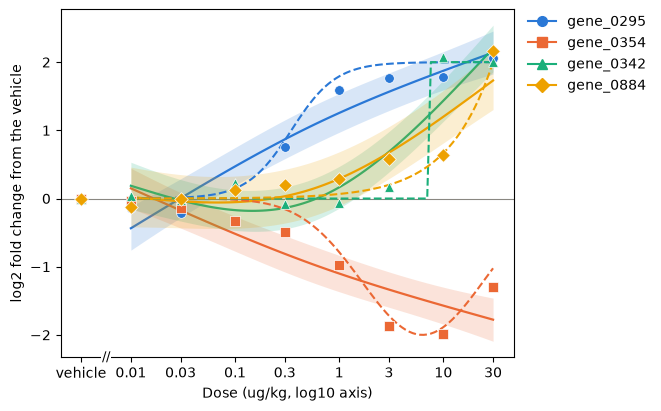

gene_0295: hill, gene_0354: log_gauss_probit, gene_0342: step, gene_0884: linear


In [7]:
called = spline.filter(spline["adjusted_p_value"] < 0.05)
truths = truth.table("Hepatocyte")
shape_of = dict(zip(truths["feature_id"].tolist(), truths["shape"].tolist()))
# The gene of smallest p-value of each of four shapes.
ordered = called.sort("p_value")["feature_id"].tolist()
shapes = ("hill", "log_gauss_probit", "step", "linear")
picked = [next(g for g in ordered if shape_of[g] == shape) for shape in shapes]
ax = plot_dose_response(result, "Hepatocyte", genes=picked)
# The true curves, dashed, in the colours of the fitted ones.
grid = np.geomspace(0.01, 30.0, 100)
true = truth.curve("Hepatocyte", picked, at=grid)
fitted = [line for line in ax.get_lines() if line.get_gid() == "curve"]
for line, values in zip(fitted, true, strict=True):
    ax.plot(axis.positions(grid), values, linestyle="--", color=line.get_color())
plt.show()
print(", ".join(f"{g}: {shape_of[g]}" for g in picked))

A spline of two columns follows its gene's dose groups only as far as its shape allows. The Hill gene (gene_0295) rises more steeply between 0.3 and 3 ug/kg than its spline, which also starts at -0.4 at 0.01 ug/kg, where the true change is 0; its band misses the true curve at 4 of the 8 doses. The bell (gene_0354) turns back above 10 ug/kg while its spline keeps falling, and its band misses the true curve from 0.1 ug/kg up. The step's spline (gene_0342) smooths its jump at 7 ug/kg, and the straight line in dose (gene_0884), which climbs only at the top doses, gets a spline that rises earlier; both bands miss at 3 and 10 ug/kg. A band holds the spline that the true means of the dose groups would give, not every true curve, so read it beside the dose points, which lie closer to the truth. With the vehicle in a group of its own, each curve starts at the lowest dose, a jump from the vehicle's 0 left of the axis break. A larger `spline_df` follows such shapes more closely at some cost in power, and the non-linearity test flags the responses that bend.

## Read next

[Which genes respond to dose](../statistics/dose_response.md#dose-response-tests) explains the four tests and how they share one fit, [Curves with a band](../statistics/dose_response.md#dose-response-curves) the curves, and [Checking a dose design](../statistics/dose_response.md#dose-design-check) the statuses of the check. [Simulated dose series with known curves](../statistics/dose_response.md#simulated-dose-series) draws series like this one at other designs, to see what a design finds before it is run.